# Question 1: Backpropagation, Optimizers, and Regularization in MLP

Dataset: UCI Dry Bean Dataset (ID: 602, 16 geometric features, 7 bean classes).

## 1. Data Loading, EDA and Preprocessing

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from ucimlrepo import fetch_ucirepo

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

RAW_DIR = Path("../data/raw")
PROC_DIR = Path("../data/processed")
FIG_DIR = Path("figures")
for d in [RAW_DIR, PROC_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""
print(f"PyTorch: {torch.__version__} | Device: {device}{gpu_name}")

PyTorch: 2.6.0+cu124 | Device: cuda (NVIDIA GeForce RTX 3050 Laptop GPU)


In [2]:
raw_path = RAW_DIR / "dry_bean_raw.csv"
if raw_path.exists():
    df_raw = pd.read_csv(raw_path)
else:
    dataset = fetch_ucirepo(id=602)
    df_raw = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
    df_raw.to_csv(raw_path, index=False)

target_col = "Class"
feature_cols = [c for c in df_raw.columns if c != target_col]

print("Raw shape:", df_raw.shape)
print("Missing values:", int(df_raw.isnull().sum().sum()))
print("Duplicate rows:", int(df_raw.duplicated().sum()))

df_clean = df_raw.drop_duplicates().reset_index(drop=True)
print("Clean shape:", df_clean.shape)
df_clean.head()

Raw shape: (13611, 17)
Missing values: 0
Duplicate rows: 68
Clean shape: (13543, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,min,mean,std,max
Area,20420.0000,53048.4604,29392.4383,254616.0000
Perimeter,524.7360,854.9934,214.7227,1985.3700
MajorAxisLength,183.6012,319.8956,85.8093,738.8602
MinorAxisLength,122.5127,202.3653,45.0516,460.1985
AspectRatio,1.0249,1.5811,0.2452,2.4303
Eccentricity,0.2190,0.7503,0.0919,0.9114
ConvexArea,20684.0000,53767.9867,29844.2485,263261.0000
EquivDiameter,161.2438,253.0341,59.3077,569.3744
Extent,0.5553,0.7498,0.0489,0.8662
Solidity,0.9192,0.9872,0.0047,0.9947


,Count,Percent (%)
Class,,
DERMASON,3546,26.18
SIRA,2636,19.46
SEKER,2027,14.97
HOROZ,1860,13.73
CALI,1630,12.04
BARBUNYA,1322,9.76
BOMBAY,522,3.85


Imbalance ratio (max/min): 6.79


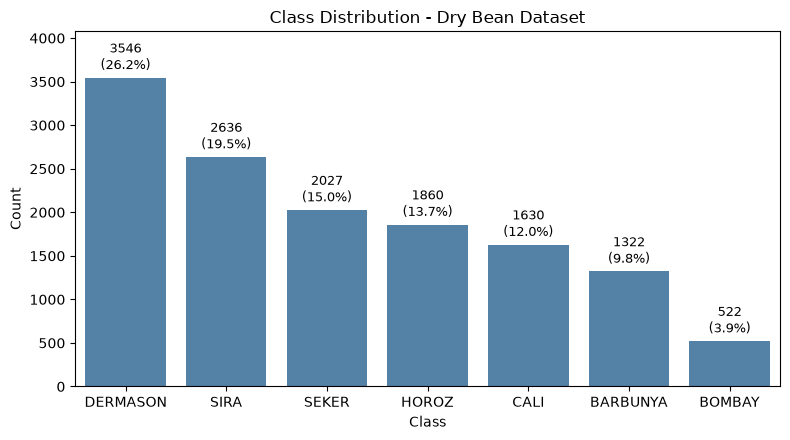

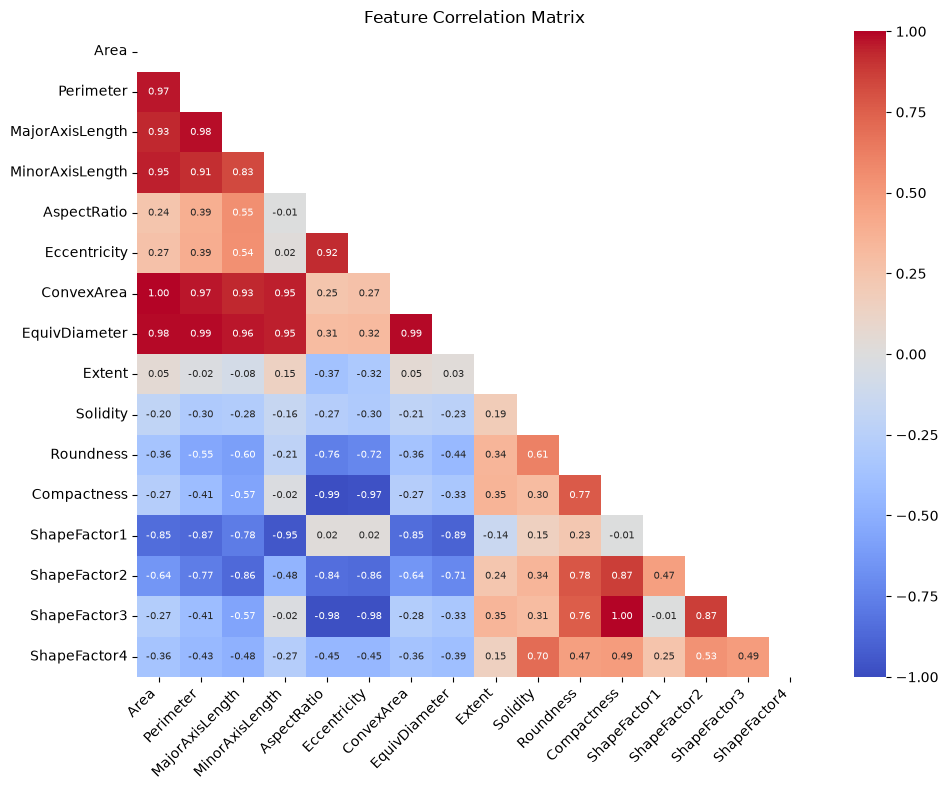

In [3]:
display(df_clean[feature_cols].describe().T[["min", "mean", "std", "max"]].round(4))

class_counts = df_clean[target_col].value_counts()
class_pct = (class_counts / len(df_clean) * 100).round(2)
display(pd.DataFrame({"Count": class_counts, "Percent (%)": class_pct}))
print(f"Imbalance ratio (max/min): {class_counts.iloc[0] / class_counts.iloc[-1]:.2f}")

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
ax.set_title("Class Distribution - Dry Bean Dataset")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
ax.set_ylim(0, class_counts.max() * 1.15)
for i, (cnt, pct) in enumerate(zip(class_counts.values, class_pct.values)):
    ax.text(i, cnt + 50, f"{cnt}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_class_distribution.png", dpi=300)
plt.show()

corr = df_clean[feature_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7.5})
plt.title("Feature Correlation Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_feature_correlation_heatmap.png", dpi=300)
plt.show()

In [4]:
le = LabelEncoder()
y_all = le.fit_transform(df_clean[target_col].values)
X_all = df_clean[feature_cols].to_numpy(dtype=np.float64)
print("Classes:", dict(enumerate(le.classes_)))

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, random_state=SEED, stratify=y_all
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

np.savez(
    PROC_DIR / "dry_bean_splits.npz",
    X_train=X_train, X_val=X_val, X_test=X_test,
    y_train=y_train.astype(np.int64),
    y_val=y_val.astype(np.int64),
    y_test=y_test.astype(np.int64),
    feature_names=np.array(feature_cols),
    class_names=le.classes_,
    scaler_mean=scaler.mean_,
    scaler_scale=scaler.scale_
)

print(f"Split sizes -> Train: {len(y_train)}, Val: {len(y_val)}, Test: {len(y_test)}")
print(f"Train scaled max |mean|: {np.abs(X_train.mean(axis=0)).max():.2e}, max |std-1|: {np.abs(X_train.std(axis=0) - 1).max():.2e}")
print(f"Val scaled max |mean|: {np.abs(X_val.mean(axis=0)).max():.4f}")

overlap = len(set(map(tuple, X_train_raw)) & (set(map(tuple, X_val_raw)) | set(map(tuple, X_test_raw))))
print("Train vs Val/Test overlapping rows:", overlap)

Classes: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Split sizes -> Train: 9480, Val: 2031, Test: 2032
Train scaled max |mean|: 3.45e-08, max |std-1|: 1.55e-06
Val scaled max |mean|: 0.0300
Train vs Val/Test overlapping rows: 0


## 2. MLP Architecture and Training Utilities

### 2.1 Theoretical Formulation: Three-Phase Backpropagation

A Multilayer Perceptron (MLP) with $L$ layers ($l = 1, \dots, L$) computes representations through three sequential phases:

#### 1. Forward Propagation ($l = 2, \dots, L$ with $a^1 = x$):
$$z^l = w^l a^{l-1} + b^l, \qquad a^l = \sigma(z^l)$$
* Hidden layers: $\sigma(z) = \text{ReLU}(z) = \max(0, z)$.
* Output layer ($l = L$): Softmax activation paired with Cross-Entropy Loss:
$$a_j^L = \frac{e^{z_j^L}}{\sum_{k=1}^K e^{z_k^L}}, \qquad C(a^L, y) = -\sum_{j=1}^K y_j \ln(a_j^L)$$

#### 2. Gradient Computation (Backward Propagation via Chain Rule):
Defining the layer error term $\delta^l \equiv \frac{\partial C}{\partial z^l}$:
* **(BP1) Output error:** $\delta^L = \nabla_a C \odot \sigma'(z^L) = a^L - y$ (Softmax + Cross-Entropy)
* **(BP2) Error propagation:** $\delta^l = \big((w^{l+1})^T \delta^{l+1}\big) \odot \sigma'(z^l)$
* **(BP3) Bias gradient:** $\frac{\partial C}{\partial b^l} = \delta^l$
* **(BP4) Weight gradient:** $\frac{\partial C}{\partial w^l} = \delta^l (a^{l-1})^T$

#### 3. Parameter Update:
On a mini-batch of $m$ samples with learning rate $\alpha$:
$$w^l \leftarrow w^l - \alpha g_{w^l}, \qquad b^l \leftarrow b^l - \alpha g_{b^l}$$

In [5]:
import copy
import time

import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

splits = np.load(PROC_DIR / "dry_bean_splits.npz", allow_pickle=True)
X_train_t = torch.tensor(splits["X_train"], dtype=torch.float32, device=device)
X_val_t = torch.tensor(splits["X_val"], dtype=torch.float32, device=device)
X_test_t = torch.tensor(splits["X_test"], dtype=torch.float32, device=device)
y_train_t = torch.tensor(splits["y_train"], dtype=torch.long, device=device)
y_val_t = torch.tensor(splits["y_val"], dtype=torch.long, device=device)
y_test_t = torch.tensor(splits["y_test"], dtype=torch.long, device=device)

class_names = list(splits["class_names"])
input_dim = X_train_t.shape[1]
num_classes = len(class_names)

class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dims, out_dim, dropout_rate=0.0):
        super().__init__()
        layers = []
        prev_dim = in_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))
            prev_dim = h_dim
        layers.append(nn.Linear(prev_dim, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

EXP1_HIDDEN = [128, 64]
EXP2_HIDDEN = [256, 256, 128]

set_seed(SEED)
init_state_exp1 = copy.deepcopy(MLP(input_dim, EXP1_HIDDEN, num_classes).state_dict())

set_seed(SEED)
init_state_exp2 = copy.deepcopy(MLP(input_dim, EXP2_HIDDEN, num_classes).state_dict())

n_params_exp1 = sum(t.numel() for t in init_state_exp1.values())
n_params_exp2 = sum(t.numel() for t in init_state_exp2.values())
print(f"Input dim: {input_dim}, Classes: {num_classes}")
print(f"MLP Exp 1 ({EXP1_HIDDEN}) params: {n_params_exp1:,}")
print(f"MLP Exp 2 ({EXP2_HIDDEN}) params: {n_params_exp2:,}")

Input dim: 16, Classes: 7
MLP Exp 1 ([128, 64]) params: 10,887
MLP Exp 2 ([256, 256, 128]) params: 103,943


In [6]:
def evaluate(model, X_t, y_t, criterion, return_preds=False):
    model.eval()
    with torch.no_grad():
        logits = model(X_t)
        loss = criterion(logits, y_t).item()
        preds = logits.argmax(dim=1).cpu().numpy()
    y_true = y_t.cpu().numpy()
    metrics = {
        "loss": loss,
        "acc": accuracy_score(y_true, preds),
        "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, preds, average="weighted", zero_division=0),
    }
    if return_preds:
        return metrics, preds
    return metrics


def train_model(
    model, init_state, optimizer_fn, X_tr, y_tr, X_va, y_va,
    epochs=100, batch_size=64, l1_lambda=0.0, l2_lambda=0.0,
    early_stopping_patience=None, min_delta=1e-4
):
    set_seed(SEED)
    model = model.to(X_tr.device)
    model.load_state_dict(copy.deepcopy(init_state))
    optimizer = optimizer_fn(model.parameters())
    criterion = nn.CrossEntropyLoss()

    n_samples = X_tr.size(0)
    bs = n_samples if (batch_size is None or batch_size >= n_samples) else batch_size

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [],
        "train_macro_f1": [], "val_macro_f1": [],
    }
    best_val_loss = float("inf")
    best_epoch = 1
    best_state = copy.deepcopy(model.state_dict())
    no_improve = 0
    stopped_epoch = epochs

    if torch.cuda.is_available() and X_tr.is_cuda:
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        if bs == n_samples:
            batches = [slice(None)]
        else:
            perm = torch.randperm(n_samples, device=X_tr.device)
            batches = [perm[s : s + bs] for s in range(0, n_samples, bs)]

        for idx in batches:
            xb, yb = X_tr[idx], y_tr[idx]
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            if l1_lambda > 0 or l2_lambda > 0:
                reg = 0.0
                for name, param in model.named_parameters():
                    if "weight" in name:
                        if l1_lambda > 0:
                            reg = reg + l1_lambda * param.abs().sum()
                        if l2_lambda > 0:
                            reg = reg + 0.5 * l2_lambda * (param ** 2).sum()
                loss = loss + reg
            loss.backward()
            optimizer.step()

        tr_m = evaluate(model, X_tr, y_tr, criterion)
        va_m = evaluate(model, X_va, y_va, criterion)
        history["train_loss"].append(tr_m["loss"])
        history["val_loss"].append(va_m["loss"])
        history["train_acc"].append(tr_m["acc"])
        history["val_acc"].append(va_m["acc"])
        history["train_macro_f1"].append(tr_m["macro_f1"])
        history["val_macro_f1"].append(va_m["macro_f1"])

        if va_m["loss"] < best_val_loss - min_delta:
            best_val_loss = va_m["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if early_stopping_patience is not None and no_improve >= early_stopping_patience:
            stopped_epoch = epoch
            break

    if torch.cuda.is_available() and X_tr.is_cuda:
        torch.cuda.synchronize()
    train_time = time.perf_counter() - t0

    if early_stopping_patience is not None:
        model.load_state_dict(best_state)

    final_train = evaluate(model, X_tr, y_tr, criterion)
    final_val = evaluate(model, X_va, y_va, criterion)
    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "stopped_epoch": stopped_epoch,
        "best_val_loss": best_val_loss,
        "final_train": final_train,
        "final_val": final_val,
        "train_time": train_time,
    }

In [7]:
xb, yb = X_train_t[:64], y_train_t[:64]
check_model = MLP(input_dim, EXP1_HIDDEN, num_classes, dropout_rate=0.0).to(device)
check_model.load_state_dict(copy.deepcopy(init_state_exp1))
criterion = nn.CrossEntropyLoss()

a_prev = check_model.net[:-1](xb)
logits = check_model.net[-1](a_prev)
loss_before = criterion(logits, yb)
print(f"Forward logits shape: {tuple(logits.shape)}")
print(f"Initial loss: {loss_before.item():.4f} (expected ~ln(7)={np.log(num_classes):.4f})")

check_model.zero_grad()
loss_before.backward()
for name, param in check_model.named_parameters():
    if "weight" in name:
        print(f"Grad norm [{name}]: {param.grad.norm().item():.6f}")

with torch.no_grad():
    probs = F.softmax(logits, dim=1)
    y_onehot = F.one_hot(yb, num_classes=num_classes).float()
    delta_L = (probs - y_onehot) / len(xb)
    dW_manual = delta_L.T @ a_prev
    db_manual = delta_L.sum(dim=0)
    w_diff = (dW_manual - check_model.net[-1].weight.grad).abs().max().item()
    b_diff = (db_manual - check_model.net[-1].bias.grad).abs().max().item()
print(f"Manual vs autograd max diff -> dW: {w_diff:.2e}, db: {b_diff:.2e}")

opt = torch.optim.SGD(check_model.parameters(), lr=0.1)
opt.step()
with torch.no_grad():
    loss_after = criterion(check_model(xb), yb).item()
print(f"After 1 SGD step -> loss_before: {loss_before.item():.4f}, loss_after: {loss_after:.4f}")

drop_model = MLP(input_dim, EXP2_HIDDEN, num_classes, dropout_rate=0.3).to(device)
drop_model.load_state_dict(copy.deepcopy(init_state_exp2))
print("Dropout model state_dict loaded cleanly:", len(drop_model.state_dict()), "tensors")

Forward logits shape: (64, 7)
Initial loss: 1.9553 (expected ~ln(7)=1.9459)
Grad norm [net.0.weight]: 0.165665
Grad norm [net.3.weight]: 0.424576
Grad norm [net.6.weight]: 0.275081
Manual vs autograd max diff -> dW: 3.73e-09, db: 1.49e-08


After 1 SGD step -> loss_before: 1.9553, loss_after: 1.9220
Dropout model state_dict loaded cleanly: 8 tensors


**Backpropagation Verification Summary:**
* Initial batch loss (`1.9553`) closely matches theoretical expectation $\ln(7) \approx 1.9459$.
* Analytical gradients (BP1–BP4) match PyTorch Autograd with maximum difference $|\Delta dW| \le 3.73 \times 10^{-9}$ and $|\Delta db| \le 1.49 \times 10^{-8}$.
* Single SGD step reduces cross-entropy loss from `1.9553` to `1.9220`.

## 3. Experiment 1: Comparison of Optimization Methods

### 3.1 Principles and Update Rules of Five Optimization Methods

Let $\theta_t$ be parameters, $g_t = \nabla_\theta C(\theta_t)$ the gradient at step $t$, and $\alpha$ the learning rate:

1. **Full-batch Gradient Descent (GD):**
   $$\theta_{t+1} = \theta_t - \alpha g_t, \qquad g_t = \frac{1}{N} \sum_{i=1}^N \nabla_\theta C^{(i)}(\theta_t)$$
   Exact gradient over all $N = 9,480$ samples; deterministic but slow per-epoch updates.

2. **SGD & Mini-batch SGD ($m = 64$):**
   $$\theta_{t+1} = \theta_t - \alpha g_t, \qquad g_t = \frac{1}{m} \sum_{i=1}^m \nabla_\theta C^{(i)}(\theta_t)$$
   Unbiased stochastic gradient estimator; balances noise exploration and GPU vectorization.

3. **SGD with Momentum ($\beta = 0.9$):**
   $$v_t = \beta v_{t-1} + g_t, \qquad \theta_{t+1} = \theta_t - \alpha v_t$$
   Accumulates velocity along consistent descent directions; dampens ravines oscillations.

4. **RMSprop ($\rho = 0.99$, PyTorch `alpha=0.99`, $\epsilon = 10^{-8}$):**
   $$s_t = \rho s_{t-1} + (1 - \rho) g_t^2, \qquad \theta_{t+1} = \theta_t - \frac{\alpha}{\sqrt{s_t} + \epsilon} g_t$$
   Adapts element-wise learning rates by tracking exponentially decaying squared gradients.

5. **Adam ($\beta_1 = 0.9, \beta_2 = 0.999, \epsilon = 10^{-8}$):**
   $$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$
   $$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}, \qquad \theta_{t+1} = \theta_t - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$
   Fuses first-moment momentum and second-moment scaling with initial bias correction.

In [8]:
optimizer_configs = [
    ("Full-batch GD", None, 100, 0.1, lambda p: torch.optim.SGD(p, lr=0.1)),
    ("Pure SGD (bs=1)", 1, 5, 0.001, lambda p: torch.optim.SGD(p, lr=0.001)),
    ("Mini-batch SGD", 64, 100, 0.01, lambda p: torch.optim.SGD(p, lr=0.01)),
    ("SGD + Momentum", 64, 100, 0.01, lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9)),
    ("RMSprop", 64, 100, 0.001, lambda p: torch.optim.RMSprop(p, lr=0.001, alpha=0.99)),
    ("Adam", 64, 100, 0.001, lambda p: torch.optim.Adam(p, lr=0.001)),
]

exp1_results = {}
rows = []
for name, bs, ep, lr_val, opt_fn in optimizer_configs:
    model = MLP(input_dim, EXP1_HIDDEN, num_classes, dropout_rate=0.0)
    res = train_model(
        model, init_state_exp1, opt_fn,
        X_train_t, y_train_t, X_val_t, y_val_t,
        epochs=ep, batch_size=bs
    )
    exp1_results[name] = res
    best_idx = res["best_epoch"] - 1
    rows.append({
        "Optimizer": name,
        "Batch Size": len(y_train_t) if bs is None else bs,
        "LR": lr_val,
        "Epochs": ep,
        "Best Epoch": res["best_epoch"],
        "Best Val Loss": round(res["best_val_loss"], 4),
        "Best Val Macro F1": round(res["history"]["val_macro_f1"][best_idx], 4),
        "Final Val Acc": round(res["final_val"]["acc"], 4),
        "Final Val Macro F1": round(res["final_val"]["macro_f1"], 4),
        "Time (s)": round(res["train_time"], 2),
    })

opt_summary_df = pd.DataFrame(rows)
display(opt_summary_df)

best_loss_row = opt_summary_df.loc[opt_summary_df["Best Val Loss"].idxmin()]
best_f1_row = opt_summary_df.loc[opt_summary_df["Best Val Macro F1"].idxmax()]
print(f"Best by Val Loss: {best_loss_row['Optimizer']} ({best_loss_row['Best Val Loss']:.4f})")
print(f"Best by Best Val Macro F1: {best_f1_row['Optimizer']} ({best_f1_row['Best Val Macro F1']:.4f})")

,Optimizer,Batch Size,LR,Epochs,Best Epoch,Best Val Loss,Best Val Macro F1,Final Val Acc,Final Val Macro F1,Time (s)
0,Full-batch GD,9480,0.100,100,100,0.4137,0.9068,0.8932,0.9068,1.25
1,Pure SGD (bs=1),1,0.001,5,5,0.2222,0.9289,0.9178,0.9289,62.91
2,Mini-batch SGD,64,0.010,100,93,0.2049,0.9378,0.9286,0.9376,21.15
3,SGD + Momentum,64,0.010,100,31,0.2007,0.9398,0.9291,0.9393,22.76
4,RMSprop,64,0.001,100,24,0.2010,0.9395,0.9104,0.9195,25.57
5,Adam,64,0.001,100,19,0.2017,0.9372,0.9222,0.9328,25.83


Best by Val Loss: SGD + Momentum (0.2007)
Best by Best Val Macro F1: SGD + Momentum (0.9398)


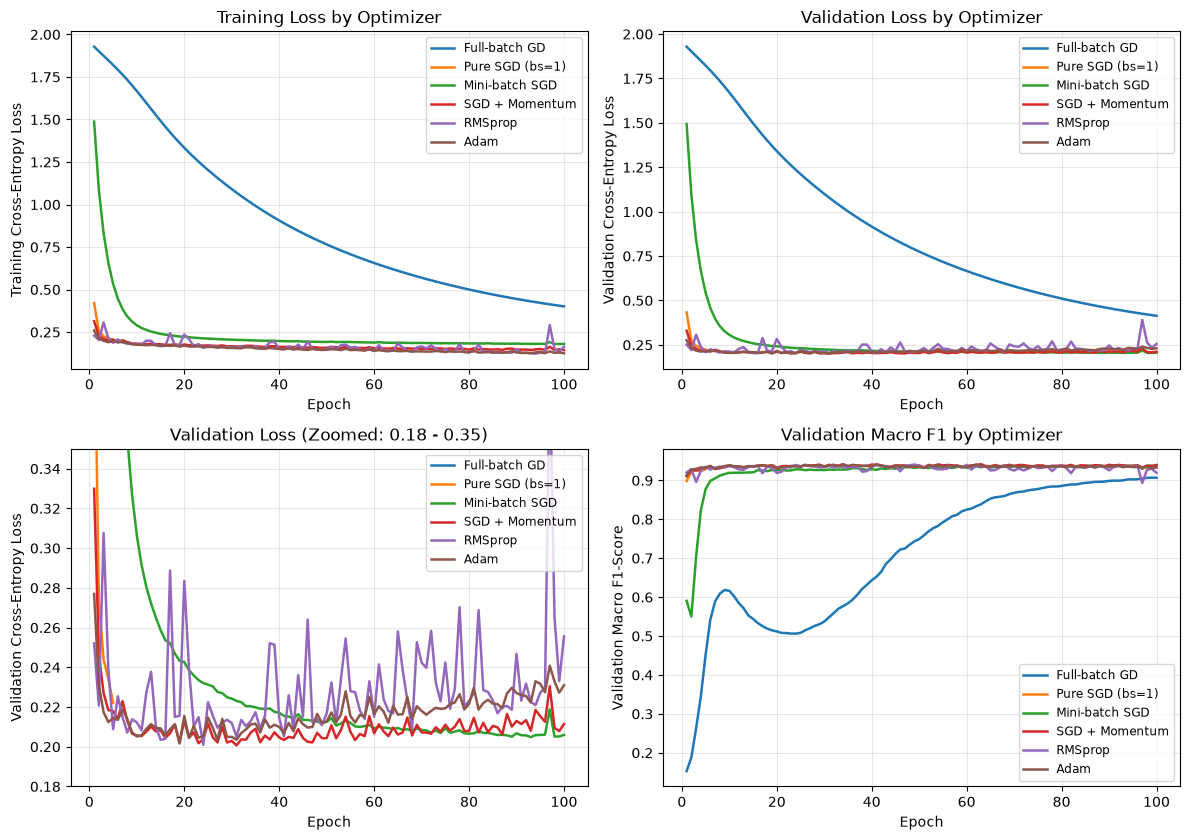

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))

for name, res in exp1_results.items():
    epochs_range = range(1, len(res["history"]["val_loss"]) + 1)
    axes[0, 0].plot(epochs_range, res["history"]["train_loss"], label=name, linewidth=1.8)
    axes[0, 1].plot(epochs_range, res["history"]["val_loss"], label=name, linewidth=1.8)
    axes[1, 0].plot(epochs_range, res["history"]["val_loss"], label=name, linewidth=1.8)
    axes[1, 1].plot(epochs_range, res["history"]["val_macro_f1"], label=name, linewidth=1.8)

axes[0, 0].set_title("Training Loss by Optimizer")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Training Cross-Entropy Loss")
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend(loc="upper right", fontsize=8.5)

axes[0, 1].set_title("Validation Loss by Optimizer")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Validation Cross-Entropy Loss")
axes[0, 1].grid(alpha=0.3)
axes[0, 1].legend(loc="upper right", fontsize=8.5)

axes[1, 0].set_title("Validation Loss (Zoomed: 0.18 - 0.35)")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Validation Cross-Entropy Loss")
axes[1, 0].set_ylim(0.18, 0.35)
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend(loc="upper right", fontsize=8.5)

axes[1, 1].set_title("Validation Macro F1 by Optimizer")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Validation Macro F1-Score")
axes[1, 1].grid(alpha=0.3)
axes[1, 1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "03_optimizer_comparison.png", dpi=300)
plt.show()

### 3.2 Discussion of Optimization Results

* **SGD + Momentum achieves best generalization:** Attains lowest Best Val Loss (`0.2007`) and highest Best Val Macro F1 (`0.9398`) at epoch 31, maintaining the lowest and most stable trajectory through epoch 100 (`Final Val Acc = 0.9291`).
* **Adam converges fastest:** Reaches near-optimal validation loss (`0.2017`) by epoch **19**. With fixed learning rate, mild late-epoch drift occurs (`Final Val Macro F1 = 0.9328`).
* **RMSprop shows late-stage instability:** Drops rapidly early (`Best Val Loss = 0.2010` at epoch 24) but suffers gradient noise spikes around epochs 97–99 due to lack of numerator momentum.
* **Full-batch GD underfits:** Training loss stays high (~0.40) after 100 epochs due to only 100 total updates, confirming slow convergence.
* **Pure SGD (bs=1) computational bottleneck:** While achieving `Val Loss = 0.2222` in 5 epochs (`47,400` updates), it takes `62.91s` due to sequential per-sample overhead on GPU.

## 4. Experiment 2: Overfitting Prevention and Final Test Evaluation

### 4.1 Overfitting Mechanism and Regularization Techniques

Overfitting occurs when high model capacity memorizes sample noise rather than generalizable patterns. Regularization techniques manage the **Bias-Variance Trade-off**:

1. **L1 Regularization (Lasso Penalty):**
   $$C_{\text{L1}} = C + \lambda_1 \sum |w| \implies \frac{\partial C_{\text{L1}}}{\partial w} = \frac{\partial C}{\partial w} + \lambda_1 \cdot \text{sign}(w)$$
   Constant penalty derivative pushes non-essential weights to exactly zero, inducing high sparsity.

2. **L2 Regularization / Weight Decay (Ridge Penalty):**
   $$C_{\text{L2}} = C + \frac{\lambda_2}{2} \sum w^2 \implies w \leftarrow (1 - \alpha \lambda_2) w - \alpha \frac{\partial C}{\partial w} \quad (\text{under SGD})$$
   Shrinks weights proportionally, distributing small smooth magnitudes without zeroing useful features.

3. **Inverted Dropout ($p = 0.3$):**
   $$\tilde{a}^l = \frac{r^l \odot a^l}{1 - p}, \qquad r^l \sim \text{Bernoulli}(1 - p) \quad (\text{Training})$$
   Zeroes out random neurons during training to prevent co-adaptation; fully active during evaluation.

4. **Early Stopping:**
   Monitors validation loss with patience $P = 15$ and threshold $\text{min\_delta} = 10^{-4}$. Halts training and restores optimal checkpoint $\theta^* = \theta_{\text{best\_epoch}}$.

In [10]:
def weight_sparsity(model, tol=1e-3):
    total = 0
    near_zero = 0
    for name, param in model.named_parameters():
        if "weight" in name:
            total += param.numel()
            near_zero += int((param.detach().abs() < tol).sum().item())
    return (near_zero / total) * 100.0


reg_configs = [
    ("Baseline", 0.0, 0.0, 0.0, None),
    ("L1 (1e-4)", 0.0, 1e-4, 0.0, None),
    ("L2 (1e-3)", 0.0, 0.0, 1e-3, None),
    ("Dropout (0.3)", 0.3, 0.0, 0.0, None),
    ("Early Stopping", 0.0, 0.0, 0.0, 15),
    ("Combined (L2+Dropout+ES)", 0.3, 0.0, 1e-3, 15),
]

exp2_results = {}
reg_rows = []
for name, dr, l1, l2, es in reg_configs:
    model = MLP(input_dim, EXP2_HIDDEN, num_classes, dropout_rate=dr)
    res = train_model(
        model, init_state_exp2, lambda p: torch.optim.Adam(p, lr=0.001),
        X_train_t, y_train_t, X_val_t, y_val_t,
        epochs=150, batch_size=64,
        l1_lambda=l1, l2_lambda=l2,
        early_stopping_patience=es
    )
    exp2_results[name] = res
    reg_rows.append({
        "Configuration": name,
        "Stopped Epoch": res["stopped_epoch"],
        "Final Train Loss": round(res["final_train"]["loss"], 4),
        "Final Val Loss": round(res["final_val"]["loss"], 4),
        "Final Train Acc": round(res["final_train"]["acc"], 4),
        "Final Val Acc": round(res["final_val"]["acc"], 4),
        "Acc Gap": round(res["final_train"]["acc"] - res["final_val"]["acc"], 4),
        "Final Val Macro F1": round(res["final_val"]["macro_f1"], 4),
        "Sparsity (%)": round(weight_sparsity(res["model"]), 2),
    })

reg_summary_df = pd.DataFrame(reg_rows)
display(reg_summary_df)

,Configuration,Stopped Epoch,Final Train Loss,Final Val Loss,Final Train Acc,Final Val Acc,Acc Gap,Final Val Macro F1,Sparsity (%)
0,Baseline,150,0.0166,0.7806,0.9961,0.9153,0.0808,0.9290,0.66
1,L1 (1e-4),150,0.1445,0.2132,0.9447,0.9301,0.0146,0.9395,96.80
2,L2 (1e-3),150,0.1524,0.2019,0.9434,0.9281,0.0152,0.9375,88.80
3,Dropout (0.3),150,0.0960,0.2642,0.9605,0.9261,0.0344,0.9377,0.56
4,Early Stopping,31,0.1615,0.2077,0.9406,0.9271,0.0135,0.9355,1.21
5,Combined (L2+Dropout+ES),25,0.1817,0.2091,0.9346,0.9261,0.0085,0.9361,5.88


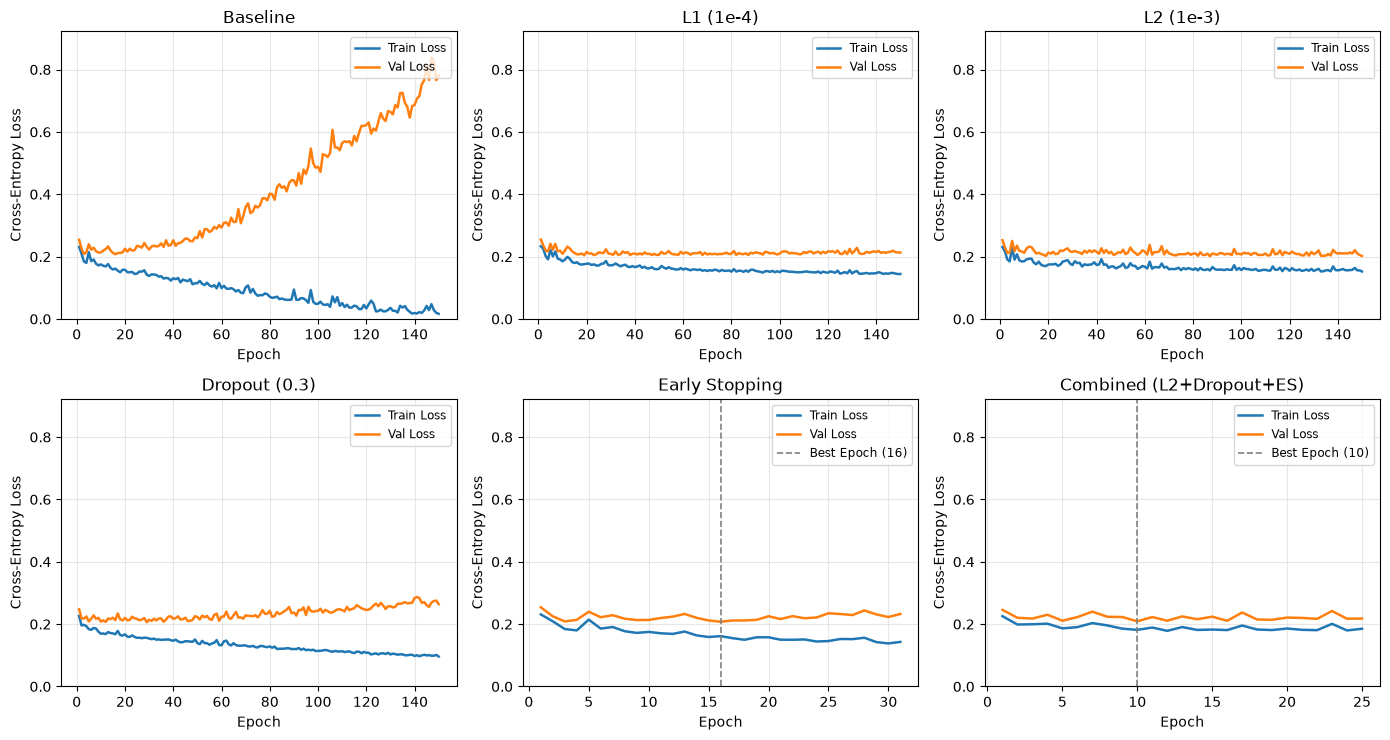

In [11]:
y_max = max(max(r["history"]["val_loss"]) for r in exp2_results.values()) * 1.1

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (name, res) in zip(axes.flat, exp2_results.items()):
    ep_range = range(1, len(res["history"]["train_loss"]) + 1)
    ax.plot(ep_range, res["history"]["train_loss"], label="Train Loss", linewidth=1.8)
    ax.plot(ep_range, res["history"]["val_loss"], label="Val Loss", linewidth=1.8)
    if name in ("Early Stopping", "Combined (L2+Dropout+ES)"):
        ax.axvline(res["best_epoch"], color="gray", linestyle="--", linewidth=1.2,
                   label=f"Best Epoch ({res['best_epoch']})")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.set_ylim(0.0, y_max)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_regularization_comparison.png", dpi=300)
plt.show()

### 4.2 Discussion of Regularization Results

* **Baseline exhibits severe overfitting:** Validation loss surges from epoch 15 to `0.7806` at epoch 150, creating an `Acc Gap` of **8.08%** (`Train Acc = 99.61%` vs `Val Acc = 91.53%`).
* **L1 Regularization (1e-4) induces strong sparsity:** Zeroes out **96.80%** of weights ($|w| < 10^{-3}$), effectively pruning collinear feature paths, achieving `Val Macro F1 = 0.9395` and `Acc Gap = 1.46%`.
* **L2 Regularization (1e-3) attains optimal validation loss:** Smooth shrinkage yields the lowest `Val Loss = 0.2019`, holds flat through epoch 150 (`Acc Gap = 1.52%`, sparsity `88.80%`), providing superior probability calibration.
* **Early Stopping halts timely:** Restores epoch 16 weights at epoch 31, preserving `Val Loss = 0.2077` and `Acc Gap = 1.35%` with minimal compute.
* **Combined configuration:** Achieves smallest `Acc Gap` (**0.85%**), though stochastic dropout fluctuations trigger early stopping at epoch 25.

Selected best model on Validation: L2 (1e-3)
Validation -> Loss: 0.2019, Acc: 0.9281, Macro F1: 0.9375

Final Test Set -> Loss: 0.2038, Acc: 0.9247, Macro F1: 0.9369, Weighted F1: 0.9246

Classification Report (Test Set):
              precision    recall  f1-score   support

    BARBUNYA     0.9350    0.9444    0.9397       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9309    0.9347    0.9328       245
    DERMASON     0.9125    0.9211    0.9167       532
       HOROZ     0.9460    0.9427    0.9443       279
       SEKER     0.9477    0.9539    0.9508       304
        SIRA     0.8837    0.8636    0.8736       396

    accuracy                         0.9247      2032
   macro avg     0.9365    0.9372    0.9369      2032
weighted avg     0.9245    0.9247    0.9246      2032



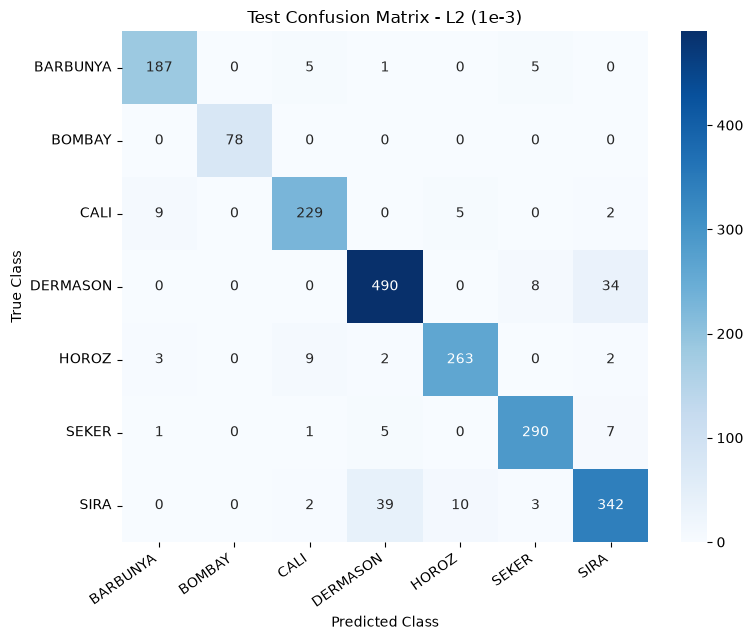

Top 3 most confused pairs (True -> Predicted):
  SIRA -> DERMASON: 39 samples
  DERMASON -> SIRA: 34 samples
  SIRA -> HOROZ: 10 samples


In [12]:
from sklearn.metrics import classification_report, confusion_matrix

candidates = dict(exp2_results)
candidates["Exp1: SGD + Momentum"] = exp1_results["SGD + Momentum"]

best_name, best_res = min(candidates.items(), key=lambda kv: kv[1]["final_val"]["loss"])
best_model = best_res["model"]

print(f"Selected best model on Validation: {best_name}")
print(
    f"Validation -> Loss: {best_res['final_val']['loss']:.4f}, "
    f"Acc: {best_res['final_val']['acc']:.4f}, "
    f"Macro F1: {best_res['final_val']['macro_f1']:.4f}"
)

criterion_eval = nn.CrossEntropyLoss()
test_metrics, y_test_pred = evaluate(best_model, X_test_t, y_test_t, criterion_eval, return_preds=True)
y_test_true = y_test_t.cpu().numpy()

print(
    f"\nFinal Test Set -> Loss: {test_metrics['loss']:.4f}, "
    f"Acc: {test_metrics['acc']:.4f}, "
    f"Macro F1: {test_metrics['macro_f1']:.4f}, "
    f"Weighted F1: {test_metrics['weighted_f1']:.4f}"
)
print("\nClassification Report (Test Set):")
print(classification_report(y_test_true, y_test_pred, target_names=class_names, digits=4, zero_division=0))

cm = confusion_matrix(y_test_true, y_test_pred)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Test Confusion Matrix - {best_name}")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_test_confusion_matrix.png", dpi=300)
plt.show()

error_pairs = []
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and cm[i, j] > 0:
            error_pairs.append((int(cm[i, j]), class_names[i], class_names[j]))
error_pairs.sort(reverse=True)
print("Top 3 most confused pairs (True -> Predicted):")
for cnt, true_c, pred_c in error_pairs[:3]:
    print(f"  {true_c} -> {pred_c}: {cnt} samples")

### 4.3 Final Test Evaluation and Error Analysis

* **Generalization consistency:** Selected model (`L2 1e-3`) achieves `Test Loss = 0.2038` and `Test Accuracy = 92.47%`, closely matching validation performance (`Val Loss = 0.2019`).
* **Macro F1 (`0.9369`) vs Weighted F1 (`0.9246`):** The minority class `BOMBAY` (`78` samples) achieves perfect classification (`F1 = 1.0000`), raising the unweighted mean, while the two dominant classes (`DERMASON` and `SIRA`, comprising 45.7% of the test set) have lower F1-scores.
* **Confusion patterns:** The primary source of error is bidirectional confusion between morphologically similar beans: `SIRA -> DERMASON` (39 samples) and `DERMASON -> SIRA` (34 samples), reflecting natural overlap in 2D geometric feature space.